##  Diplomado en Ciencia de Datos

<h1 align = 'center'> Métodos de ensamble </h1>

Los métodos de ensamble combinan varios modelos base (*weak learners*) para obtener un modelo final más preciso y estable que cualquiera de ellos por separado. La idea de fondo es el balance **sesgo–varianza**: promediar modelos con errores poco correlacionados reduce la varianza, y entrenar modelos de forma secuencial para corregir errores previos reduce el sesgo.

**Familias de métodos de ensamble:**

1. **Voting / Averaging:** se entrenan en paralelo modelos *distintos* (p. ej. regresión logística, KNN y SVM) y se combinan sus salidas. En clasificación, la votación puede ser *dura* (`hard`: gana la clase más votada) o *suave* (`soft`: se promedian las probabilidades predichas y se elige la clase con mayor probabilidad media). En regresión se promedian las predicciones.

2. **Bagging (Bootstrap Aggregating):** se generan múltiples conjuntos de entrenamiento mediante muestreo con reemplazo (bootstrap) y se entrena una instancia del *mismo* algoritmo en cada uno. Las predicciones se agregan por votación o promedio. Los modelos son independientes entre sí, por lo que se pueden entrenar en paralelo. Reduce principalmente la **varianza**. Ejemplo: Random Forest.

3. **Boosting:** enfoque *secuencial* donde cada modelo nuevo se concentra en los errores cometidos por el ensamble actual. Reduce principalmente el **sesgo** (aunque también puede reducir varianza). Ejemplos: AdaBoost, Gradient Boosting, XGBoost, LightGBM y CatBoost.

4. **Stacking:** las predicciones de varios modelos base se usan como variables de entrada de un *meta-modelo* que aprende cómo combinarlas.

**Diagrama de ensamble para problema de regresión**
<img src='../img/ensamble_reg.png'>

**Diagrama de ensamble para problema de clasificación**
<img src='../img/ensamble_clf.png'>

**Ventajas de los Métodos de Ensamble:**

1. **Mejora de la precisión:** suelen superar al mejor de sus modelos base individuales.

2. **Robustez:** al combinar múltiples modelos son más estables ante el ruido en los datos. El bagging en particular reduce el sobreajuste; el boosting, en cambio, **sí puede sobreajustar** si se usan demasiados árboles o árboles muy profundos, por lo que requiere regularización y *early stopping*.

3. **Datos desbalanceados:** pueden ayudar, pero no lo resuelven por sí solos; normalmente se combinan con pesos de clase (`class_weight`, `scale_pos_weight`, `auto_class_weights`) o remuestreo, y con métricas adecuadas (F1, PR-AUC) en lugar de solo la exactitud.

4. **Importancia de variables:** los ensambles de árboles (Random Forest y boosting) entregan medidas de importancia de características que ayudan a interpretar el modelo.

**Consideraciones al Usar Métodos de Ensamble:**

1. **Costo computacional:** entrenar y almacenar muchos modelos base es más costoso en tiempo y memoria que un modelo único (el boosting, además, es secuencial).

2. **Hiperparámetros:** además de los de los modelos base, el ensamble tiene los propios (número de modelos, tasa de aprendizaje, submuestreo, etc.) que deben ajustarse con validación cruzada.

3. **Interpretabilidad:** a medida que aumenta la complejidad del ensamble, explicar una predicción individual se vuelve más difícil que con un modelo simple (regresión lineal o un único árbol). Herramientas como SHAP ayudan a mitigarlo.

<h2> Modelo matemático </h2>

Consideremos el siguiente problema de regresión: sea $f(\mathbf{x})$ la función que queremos predecir, donde $\mathbf{x}$ representa las características de entrada e $y$ la etiqueta verdadera. Supongamos que tenemos un conjunto de datos de entrenamiento

$$D = \{(\mathbf{x}_1, y_1), (\mathbf{x}_2, y_2), ..., (\mathbf{x}_n, y_n)\}$$

Ahora, definimos un modelo débil $h(\mathbf{x})$ que aproxima la función $f(\mathbf{x})$ con cierto error, es decir, $h(\mathbf{x}) \approx f(\mathbf{x}) + \epsilon$, donde $\epsilon$ es el error del modelo.

El objetivo de los métodos de ensamble es combinar múltiples modelos débiles $h_{1}(\mathbf{x}), h_2(\mathbf{x}), ..., h_M(\mathbf{x})$ para obtener una predicción más precisa $F(\mathbf{x})$:

$$F(\mathbf{x}) = \alpha_1 h_1(\mathbf{x}) + \alpha_2 h_2(\mathbf{x}) + ... + \alpha_M h_M(\mathbf{x})$$

donde $\alpha_1, \alpha_2, ..., \alpha_M$ son los pesos asignados a cada modelo débil, que pueden ser iguales (voting, bagging) o diferentes (AdaBoost, stacking).

**¿Por qué promediar ayuda?** Si los $M$ modelos tienen varianza $\sigma^2$ y correlación promedio entre sus errores $\rho$, la varianza del promedio es

$$\text{Var}\left(\frac{1}{M}\sum_{m=1}^{M} h_m(\mathbf{x})\right) = \rho\,\sigma^2 + \frac{1-\rho}{M}\,\sigma^2$$

Al aumentar $M$ desaparece el segundo término, pero el primero permanece: **la ganancia depende de qué tan diversos (poco correlacionados) sean los modelos**. Por eso Random Forest, además del bootstrap, elige un subconjunto aleatorio de variables en cada división: para disminuir $\rho$.

<h2> Ejemplos de clasificador por votos </h2>

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.


In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib scikit-learn xgboost lightgbm catboost


/tmp/claude-1000/-home-juanf-Projects-Material-Ciencia-de-Datos/80c87bab-8ddf-4aef-979f-ecfd95e1fe15/scratchpad/env/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             accuracy_score, f1_score)

import warnings

warnings.filterwarnings('ignore')

In [3]:
from sklearn.datasets import load_breast_cancer

In [4]:
breast_cancer = load_breast_cancer(as_frame=True)

In [5]:
cancer_df = pd.DataFrame(breast_cancer['data'], 
                         columns = breast_cancer['feature_names'])


In [6]:
x_cols = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']
X = cancer_df[x_cols]
y = breast_cancer['target']
X

,mean radius,mean texture,mean perimeter,mean area,mean smoothness
0,17.99,10.38,122.80,1001.0,0.11840
1,20.57,17.77,132.90,1326.0,0.08474
2,19.69,21.25,130.00,1203.0,0.10960
3,11.42,20.38,77.58,386.1,0.14250
4,20.29,14.34,135.10,1297.0,0.10030
...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100
565,20.13,28.25,131.20,1261.0,0.09780
566,16.60,28.08,108.30,858.1,0.08455
567,20.60,29.33,140.10,1265.0,0.11780


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Usaremos el conjunto de datos *Breast Cancer* de scikit-learn y, para mantener el ejemplo simple, solo cinco variables. Los modelos de los siguientes ejemplos se evalúan sobre el mismo conjunto de prueba (`X_test`), y la partición es **estratificada** para conservar la proporción de clases.

**Importante:** KNN, SVM y regresión logística son sensibles a la escala de las variables (aquí `mean area` está en el orden de $10^3$ y `mean smoothness` en el de $10^{-1}$). Por eso cada modelo se envuelve en un `Pipeline` con `StandardScaler`, de modo que el escalado se ajusta solo con los datos de entrenamiento (sin fuga de información) dentro de cada partición de la validación cruzada. Los modelos basados en árboles, en cambio, **no necesitan escalado**.

En un `VotingClassifier` con `voting='hard'` cada modelo emite una clase y gana la mayoritaria; con `voting='soft'` se promedian las probabilidades (`predict_proba`), lo que suele funcionar mejor si los modelos están bien calibrados. También se pueden asignar pesos con el parámetro `weights`.

In [8]:
def con_escala(modelo):
    return Pipeline([('scaler', StandardScaler()), ('clf', modelo)])


models = [
    ('lr', con_escala(LogisticRegression())),
    ('knn', con_escala(KNeighborsClassifier(n_neighbors=5))),
    ('svc', con_escala(SVC()))
]

voting_clf = VotingClassifier(
    estimators=models,
    voting='hard'
)

In [9]:
voting_clf.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('knn', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[Pipeline(step...egression())]), Pipeline(step...lassifier())]), Pipeline(step...clf', SVC())])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['mean radius','mean texture','mean perimeter','mean area', 'mean smoothness']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [10]:
y_pred = voting_clf.predict(X_test)

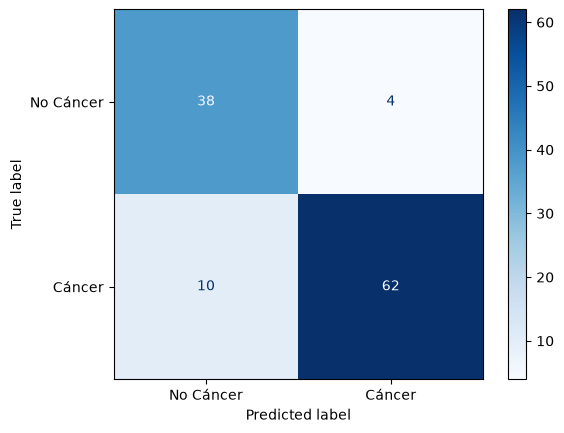

In [11]:
disp = ConfusionMatrixDisplay.from_estimator(
    voting_clf,
    X_test,
    y_test,
    display_labels=['No Cáncer', 'Cáncer'],
    cmap=plt.cm.Blues,
)

In [12]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.90      0.84        42
           1       0.94      0.86      0.90        72

    accuracy                           0.88       114
   macro avg       0.87      0.88      0.87       114
weighted avg       0.88      0.88      0.88       114



In [13]:
for name, clf in voting_clf.named_estimators_.items():
    print(name, "=", clf.score(X_test, y_test))

lr = 0.8596491228070176
knn = 0.8947368421052632
svc = 0.8771929824561403


Ajustamos los hiperparámetros de los modelos internos con `GridSearchCV`. Los parámetros se nombran como `<modelo>__<paso>__<parámetro>`. Como `degree` solo tiene efecto con `kernel='poly'`, se usa una **lista de grillas** para no evaluar combinaciones redundantes.

In [14]:
param_grid = [
    {   # Kernels sin grado
        'knn__clf__n_neighbors': [3, 5, 11, 20],
        'svc__clf__C': [0.1, 1.0, 10.0],
        'svc__clf__kernel': ['linear', 'rbf'],
    },
    {   # Kernel polinomial: aquí sí importa el grado
        'knn__clf__n_neighbors': [3, 5, 11, 20],
        'svc__clf__C': [0.1, 1.0, 10.0],
        'svc__clf__kernel': ['poly'],
        'svc__clf__degree': [2, 3, 5],
    },
]

In [15]:
from sklearn.model_selection import GridSearchCV

In [16]:
grid_search = GridSearchCV(estimator=voting_clf, param_grid=param_grid, cv=5, n_jobs=-1)

In [17]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","VotingClassif...', SVC())]))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'knn__clf__n_neighbors': [3, 5, ...], 'svc__clf__C': [0.1, 1.0, ...], 'svc__clf__kernel': ['linear', 'rbf']}, {'knn__clf__n_neighbors': [3, 5, ...], 'svc__clf__C': [0.1, 1.0, ...], 'svc__clf__degree': [2, 3, ...], 'svc__clf__kernel': ['poly']}]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callab

In [18]:
best_params = grid_search.best_params_
best_score = grid_search.best_score_

In [19]:
print("Mejores parámetros:", best_params)
print("Mejor exactitud:", best_score)

Mejores parámetros: {'knn__clf__n_neighbors': 3, 'svc__clf__C': 0.1, 'svc__clf__kernel': 'linear'}
Mejor exactitud: 0.9472527472527472


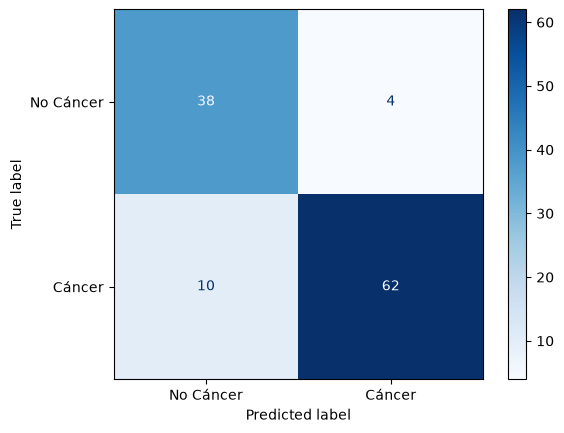

In [20]:
disp = ConfusionMatrixDisplay.from_estimator(
    grid_search,
    X_test,
    y_test,
    display_labels=['No Cáncer', 'Cáncer'],
    cmap=plt.cm.Blues,
)

Ahora con **votación suave**: las probabilidades de los tres modelos se promedian. `SVC` requiere `probability=True` para exponer `predict_proba`.

In [21]:
soft_clf = VotingClassifier(
    estimators=[
        ('lr', con_escala(LogisticRegression())),
        ('knn', con_escala(KNeighborsClassifier(n_neighbors=5))),
        ('svc', con_escala(SVC(probability=True, random_state=42)))
    ],
    voting='soft'
)
soft_clf.fit(X_train, y_train)

print('Voting hard :', voting_clf.score(X_test, y_test))
print('Voting soft :', soft_clf.score(X_test, y_test))

Voting hard : 0.8771929824561403
Voting soft : 0.8771929824561403


Para comparar al final todos los métodos de forma homogénea, definimos una función auxiliar que entrena un modelo, lo evalúa en el conjunto de prueba y guarda exactitud, F1 y tiempo de entrenamiento.

In [22]:
resultados = {}


def evaluar(nombre, modelo, X_fit=None, y_fit=None, **fit_kwargs):
    """Entrena, evalúa sobre X_test y guarda las métricas en `resultados`."""
    X_fit = X_train if X_fit is None else X_fit
    y_fit = y_train if y_fit is None else y_fit
    t0 = time.perf_counter()
    modelo.fit(X_fit, y_fit, **fit_kwargs)
    tiempo = time.perf_counter() - t0
    y_pred = modelo.predict(X_test)
    resultados[nombre] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'tiempo_fit_s': tiempo,
    }
    return y_pred


# Partición de validación (dentro del entrenamiento) para early stopping en boosting
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

<h2> Bagging </h2>

En *bagging* se entrena el mismo estimador sobre $M$ muestras bootstrap y se agregan las predicciones. Cada muestra bootstrap deja fuera en promedio ~36.8 % de las observaciones ($\left(1-\tfrac{1}{n}\right)^n \to e^{-1}$); esas observaciones *out-of-bag* (OOB) sirven como un conjunto de validación gratuito (`oob_score=True`).

Un árbol profundo tiene sesgo bajo pero varianza alta, por lo que es el candidato ideal para bagging.

| Hiperparámetro | Qué controla |
|---|---|
| `estimator` | Modelo base a replicar (por defecto un árbol de decisión). |
| `n_estimators` | Número de modelos. Más es casi siempre mejor (rendimientos decrecientes), solo cuesta tiempo. |
| `max_samples` | Fracción (o número) de muestras de cada bootstrap. |
| `max_features` | Fracción de variables que ve cada modelo (aumenta la diversidad). |
| `bootstrap` | Muestreo con (`True`) o sin reemplazo. |
| `oob_score` | Calcula la exactitud *out-of-bag*. |

In [23]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

arbol = DecisionTreeClassifier(random_state=42)
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    max_samples=1.0,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=42,
)

evaluar('Árbol de decisión', arbol)
evaluar('Bagging (árboles)', bagging)

print(f'Exactitud OOB del bagging: {bagging.oob_score_:.3f}')
pd.DataFrame(resultados).T[['accuracy', 'f1']]

Exactitud OOB del bagging: 0.925


,accuracy,f1
Árbol de decisión,0.885965,0.905109
Bagging (árboles),0.894737,0.913043


<h2> Bosques aleatorios </h2>

El modelo de bosques aleatorios (Random Forest, en inglés) es un ensamble de árboles de decisión basado en bagging con un ingrediente adicional: en **cada división** de cada árbol solo se considera un subconjunto aleatorio de variables. Esto decorrela los árboles (reduce $\rho$) y mejora la ganancia del promedio.

| Hiperparámetro | Qué controla | Guía |
|---|---|---|
| `n_estimators` | Número de árboles. | 100–1000. Más árboles no sobreajustan; solo aumentan el costo. |
| `max_features` | Variables candidatas en cada división (`'sqrt'` por defecto en clasificación). | Valores bajos → árboles más diversos (menos varianza, más sesgo). |
| `max_depth` | Profundidad máxima. | `None` (hasta hojas puras) suele estar bien; limitarla regulariza. |
| `min_samples_leaf` / `min_samples_split` | Tamaño mínimo de hoja / de nodo para dividir. | Aumentarlos suaviza el modelo y reduce sobreajuste. |
| `max_samples` | Tamaño del bootstrap (con `bootstrap=True`). | Menor → más diversidad y entrenamiento más rápido. |
| `class_weight` | Pesos por clase (`'balanced'`). | Útil con clases desbalanceadas. |
| `oob_score` | Estimación OOB del desempeño. | Alternativa económica a la validación cruzada. |

<img src = '../img/RF.png'>

In [24]:
from sklearn.ensemble import RandomForestClassifier

In [25]:
clf = RandomForestClassifier(n_estimators=300, max_depth=None,
    min_samples_split=2, oob_score=True, n_jobs=-1, random_state=0)

In [26]:
y_pred = evaluar('Random Forest', clf)
print(f'Exactitud OOB: {clf.oob_score_:.3f}')

Exactitud OOB: 0.927


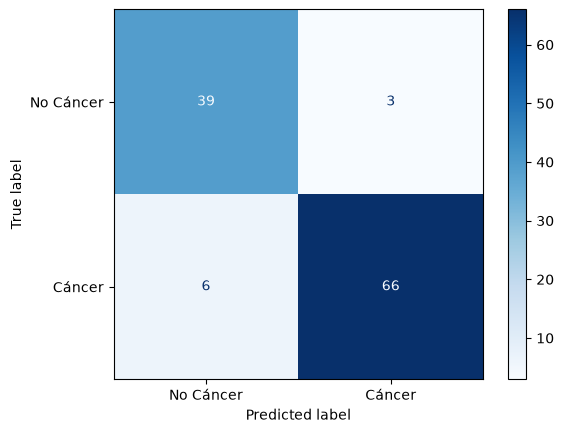

In [27]:
disp = ConfusionMatrixDisplay.from_estimator(
    clf,
    X_test,
    y_test,
    display_labels=['No Cáncer', 'Cáncer'],
    cmap=plt.cm.Blues,
)

In [28]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.93      0.90        42
           1       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



Los bosques aleatorios permiten medir la **importancia de las variables** (reducción media de impureza). Conviene recordar que esta medida favorece variables continuas o de alta cardinalidad y que, con variables correlacionadas (como radio, perímetro y área), la importancia se reparte entre ellas; la importancia por permutación (`sklearn.inspection.permutation_importance`) es una alternativa más robusta.

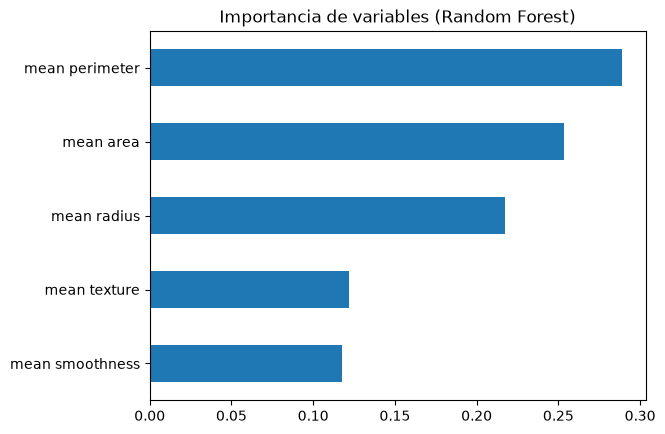

In [29]:
importancias = pd.Series(clf.feature_importances_, index=X.columns).sort_values()
importancias.plot.barh(title='Importancia de variables (Random Forest)')
plt.show()

<h2> Boosting </h2>

En *boosting* los modelos débiles (típicamente árboles poco profundos) se entrenan **uno tras otro**, y cada uno intenta corregir lo que el ensamble acumulado hasta ese momento aún hace mal. El modelo final es una suma ponderada

$$F_M(\mathbf{x}) = \sum_{m=1}^{M} \alpha_m h_m(\mathbf{x})$$

| | Bagging / Random Forest | Boosting |
|---|---|---|
| Entrenamiento | Paralelo, modelos independientes | Secuencial, cada modelo depende del anterior |
| Modelo base | Árboles profundos (varianza alta) | Árboles pequeños (sesgo alto) |
| Reduce principalmente | Varianza | Sesgo |
| Riesgo de sobreajuste al aumentar $M$ | Bajo | Alto (requiere `learning_rate`, regularización y early stopping) |
| Sensibilidad a ruido/outliers | Baja | Mayor |

Los algoritmos difieren en *cómo* definen "lo que el ensamble hace mal": AdaBoost lo hace reponderando observaciones; Gradient Boosting (y XGBoost, LightGBM, CatBoost) ajusta el siguiente modelo al **gradiente de la función de pérdida**.

<h2> AdaBoost </h2>

**AdaBoost** (*Adaptive Boosting*, Freund & Schapire, 1997) mantiene un peso $w_i$ por observación. En cada iteración entrena un modelo débil con esos pesos y luego **aumenta el peso de las observaciones mal clasificadas**, de modo que el siguiente modelo se concentra en los casos difíciles.

Algoritmo (clasificación binaria con $y_i \in \{-1,+1\}$):

1. Inicializar $w_i = 1/n$.
2. Para $m = 1, \dots, M$:
   - Entrenar $h_m(\mathbf{x})$ usando los pesos $w_i$.
   - Calcular el error ponderado: $\varepsilon_m = \dfrac{\sum_i w_i\,\mathbb{1}[h_m(\mathbf{x}_i)\neq y_i]}{\sum_i w_i}$.
   - Calcular el peso del modelo: $\alpha_m = \dfrac{1}{2}\ln\dfrac{1-\varepsilon_m}{\varepsilon_m}$. Un modelo mejor que el azar ($\varepsilon_m<0.5$) tiene $\alpha_m>0$, y mientras menor su error, mayor su voz en la decisión final.
   - Actualizar los pesos: $w_i \leftarrow w_i \exp\left(-\alpha_m\, y_i\, h_m(\mathbf{x}_i)\right)$ y normalizar para que sumen 1. Los aciertos pierden peso y los errores lo ganan.
3. Predicción: $H(\mathbf{x}) = \text{sign}\left(\sum_{m=1}^{M}\alpha_m h_m(\mathbf{x})\right)$.

AdaBoost equivale a minimizar la **pérdida exponencial** $L(y,F)=e^{-yF}$ de forma aditiva por etapas, lo que lo conecta con Gradient Boosting. (scikit-learn implementa la variante multiclase SAMME, cuyo $\alpha_m = \eta\left[\ln\frac{1-\varepsilon_m}{\varepsilon_m} + \ln(K-1)\right]$ difiere solo en constantes, con $\eta$ = `learning_rate` y $K$ = número de clases.)

**Hiperparámetros principales (`AdaBoostClassifier` / `AdaBoostRegressor`)**

| Hiperparámetro | Qué controla | Guía |
|---|---|---|
| `estimator` | Modelo débil. Por defecto un *stump* (`DecisionTreeClassifier(max_depth=1)`). | Árboles de profundidad 1–3. Modelos muy complejos que ya ajustan perfecto dejan de aportar. |
| `n_estimators` | Número máximo de iteraciones (default 50). | Se compensa con `learning_rate`. Si el error llega a 0 el entrenamiento se detiene antes. |
| `learning_rate` | Factor que reduce la contribución de cada modelo (default 1.0). | Valores menores (0.1–0.5) exigen más estimadores pero generalizan mejor: el clásico *trade-off* `learning_rate` ↔ `n_estimators`. |

AdaBoost es sensible a **ruido y outliers**: como sigue aumentando el peso de las observaciones difíciles, puede terminar "obsesionado" con datos mal etiquetados.

In [30]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),  # stumps
    n_estimators=200,
    learning_rate=0.5,
    random_state=42,
)

y_pred = evaluar('AdaBoost', ada)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.93      0.86        42
           1       0.95      0.86      0.91        72

    accuracy                           0.89       114
   macro avg       0.87      0.89      0.88       114
weighted avg       0.90      0.89      0.89       114



Con `staged_score` se observa cómo evoluciona la exactitud a medida que se agregan modelos, y cómo `learning_rate` cambia la velocidad de aprendizaje.

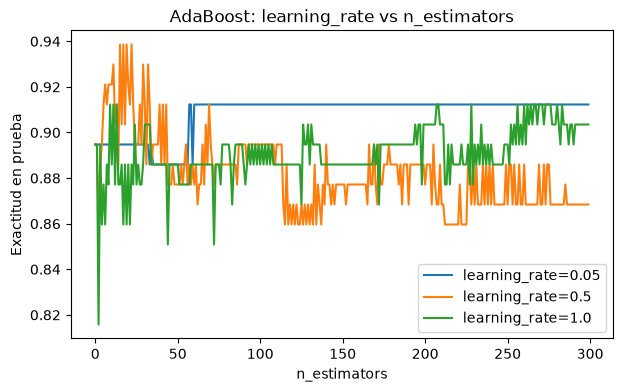

In [31]:
fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.05, 0.5, 1.0]:
    m = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                           n_estimators=300, learning_rate=lr, random_state=42)
    m.fit(X_train, y_train)
    ax.plot(list(m.staged_score(X_test, y_test)), label=f'learning_rate={lr}')
ax.set_xlabel('n_estimators')
ax.set_ylabel('Exactitud en prueba')
ax.set_title('AdaBoost: learning_rate vs n_estimators')
ax.legend()
plt.show()

<h2> Gradient Boosting </h2>

**Gradient Boosting** (Friedman, 2001) generaliza el boosting a cualquier función de pérdida diferenciable $L(y, F(\mathbf{x}))$. Se interpreta como un **descenso por gradiente en el espacio de funciones**: en cada etapa se agrega un árbol que apunta en la dirección en la que la pérdida disminuye más rápido.

Algoritmo:

1. Inicializar con una constante: $F_0(\mathbf{x}) = \arg\min_{\gamma}\sum_i L(y_i,\gamma)$ (la media para MSE; el log-odds de la clase positiva para log-loss).
2. Para $m = 1,\dots,M$:
   - Calcular los **pseudo-residuos** (menos el gradiente de la pérdida respecto a la predicción actual):
   $$r_{im} = -\left[\frac{\partial L\big(y_i, F(\mathbf{x}_i)\big)}{\partial F(\mathbf{x}_i)}\right]_{F=F_{m-1}}$$
   - Ajustar un árbol de regresión $h_m(\mathbf{x})$ a $\{(\mathbf{x}_i, r_{im})\}$.
   - Actualizar: $F_m(\mathbf{x}) = F_{m-1}(\mathbf{x}) + \eta\, h_m(\mathbf{x})$, con $\eta$ la tasa de aprendizaje (*shrinkage*).
3. Predecir con $F_M(\mathbf{x})$ (en clasificación, pasando por la sigmoide/softmax).

Casos particulares:
- **Error cuadrático** $L=\tfrac12(y-F)^2$: $r_{im}=y_i-F_{m-1}(\mathbf{x}_i)$, es decir, cada árbol ajusta los *residuos* del modelo actual.
- **Log-loss binaria**: $r_{im}=y_i-\sigma\big(F_{m-1}(\mathbf{x}_i)\big)$, la diferencia entre la etiqueta y la probabilidad predicha.
- Con la pérdida exponencial se recupera AdaBoost.

Veamos la idea con un ejemplo de regresión implementado "a mano": cada árbol pequeño ajusta los residuos y la curva se acerca a los datos.

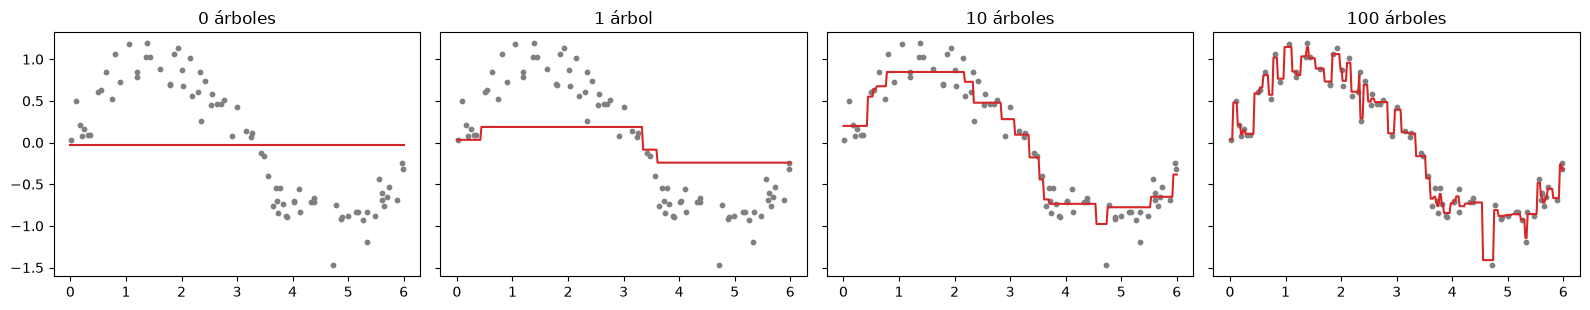

In [32]:
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(0)
x_toy = np.sort(rng.uniform(0, 6, 80))
y_toy = np.sin(x_toy) + rng.normal(0, 0.2, x_toy.size)
x_grid = np.linspace(0, 6, 300)


def boosting_manual(n_arboles, eta=0.3, max_depth=2):
    F = np.full_like(y_toy, y_toy.mean())          # F_0: constante
    F_grid = np.full_like(x_grid, y_toy.mean())
    for _ in range(n_arboles):
        residuos = y_toy - F                       # pseudo-residuos (MSE)
        arbol = DecisionTreeRegressor(max_depth=max_depth).fit(x_toy[:, None], residuos)
        F += eta * arbol.predict(x_toy[:, None])
        F_grid += eta * arbol.predict(x_grid[:, None])
    return F_grid


fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, n in zip(axes, [0, 1, 10, 100]):
    ax.scatter(x_toy, y_toy, s=10, color='gray')
    ax.plot(x_grid, boosting_manual(n), color='tab:red')
    ax.set_title(f'{n} árboles' if n != 1 else '1 árbol')
plt.tight_layout()
plt.show()

**Hiperparámetros principales (`GradientBoostingClassifier` / `GradientBoostingRegressor`)**

| Hiperparámetro | Qué controla | Guía |
|---|---|---|
| `n_estimators` | Número de árboles $M$ (default 100). | Es el más importante junto con `learning_rate`. Determinarlo con *early stopping* (`n_iter_no_change`, `validation_fraction`). |
| `learning_rate` | Encogimiento $\eta$ de cada árbol (default 0.1). | Valores pequeños (0.01–0.1) generalizan mejor, pero necesitan más árboles. |
| `max_depth` | Profundidad de cada árbol (default 3). | Controla el orden de las interacciones que puede capturar; típicamente 3–8. Árboles más profundos → más sobreajuste. |
| `subsample` | Fracción de filas usada en cada árbol (default 1.0). | Valores < 1 (p. ej. 0.5–0.8) dan *stochastic gradient boosting*: reduce varianza y acelera. |
| `max_features` | Variables candidatas por división. | Agrega aleatoriedad, como en Random Forest. |
| `min_samples_leaf` / `min_samples_split` | Tamaño mínimo de hoja / nodo. | Regularizan la complejidad de cada árbol. |
| `loss` | Función de pérdida (`'log_loss'`, `'exponential'`; en regresión `'squared_error'`, `'absolute_error'`, `'huber'`, `'quantile'`). | Elegir según el problema y la robustez a outliers. |
| `n_iter_no_change` | Detiene el entrenamiento si la pérdida de validación no mejora. | Evita sobreajuste y ahorra tiempo. |

Regla práctica: **bajar `learning_rate` y subir `n_estimators` casi siempre mejora el resultado** a cambio de más tiempo de cómputo.

In [33]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    min_samples_leaf=5,
    n_iter_no_change=20,        # early stopping interno
    validation_fraction=0.1,
    random_state=42,
)

y_pred = evaluar('Gradient Boosting (sklearn)', gb)
print(f'Árboles realmente entrenados: {gb.n_estimators_}')
print(classification_report(y_test, y_pred))

Árboles realmente entrenados: 98
              precision    recall  f1-score   support

           0       0.81      0.93      0.87        42
           1       0.95      0.88      0.91        72

    accuracy                           0.89       114
   macro avg       0.88      0.90      0.89       114
weighted avg       0.90      0.89      0.90       114



El efecto de `learning_rate`: con valores altos el error de prueba baja rápido pero se estanca (o sube por sobreajuste); con valores bajos la mejora es más lenta, pero más estable.

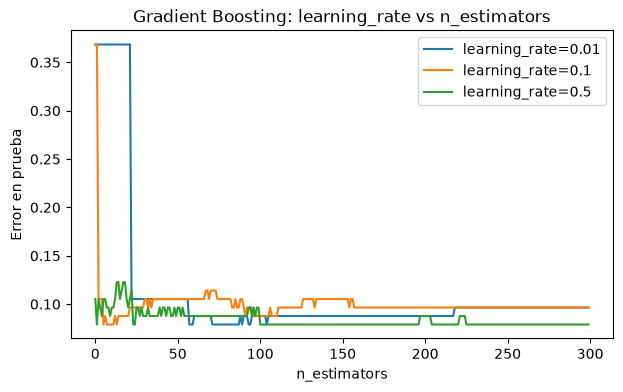

In [34]:
fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.01, 0.1, 0.5]:
    m = GradientBoostingClassifier(n_estimators=300, learning_rate=lr,
                                   max_depth=3, random_state=42).fit(X_train, y_train)
    err = [1 - accuracy_score(y_test, p) for p in m.staged_predict(X_test)]
    ax.plot(err, label=f'learning_rate={lr}')
ax.set_xlabel('n_estimators')
ax.set_ylabel('Error en prueba')
ax.set_title('Gradient Boosting: learning_rate vs n_estimators')
ax.legend()
plt.show()

> **Nota:** scikit-learn también ofrece `HistGradientBoostingClassifier/Regressor`, inspirado en LightGBM (histogramas, soporte nativo de valores faltantes y de variables categóricas, early stopping por defecto en datasets grandes). Es mucho más rápido que `GradientBoostingClassifier` para $n > 10\,000$ y no requiere instalar nada adicional.

Las tres librerías siguientes (**XGBoost, LightGBM y CatBoost**) son implementaciones de Gradient Boosting altamente optimizadas, que agregan regularización, aleatoriedad, manejo de valores faltantes, paralelismo y soporte para GPU. Todas tienen una interfaz compatible con scikit-learn (`fit`, `predict`, `predict_proba`), por lo que funcionan con `Pipeline`, `GridSearchCV`, etc.

<h3> XGBoost </h3>

**XGBoost** (*eXtreme Gradient Boosting*, Chen & Guestrin, 2016) mejora el Gradient Boosting clásico con:

- **Objetivo regularizado** y aproximación de **segundo orden** (usa gradiente $g_i$ y hessiana $h_i$ de la pérdida).
- Un algoritmo de división basado en la ganancia que incorpora directamente la regularización.
- Manejo nativo de valores faltantes (aprende la dirección por defecto de cada división), búsqueda de cortes por histogramas (`tree_method='hist'`), paralelismo y soporte de GPU.
- Crecimiento de árboles por **niveles** (*level-wise*, `grow_policy='depthwise'`) por defecto.

En la etapa $t$ se minimiza

$$\text{Obj}^{(t)} \approx \sum_{i}\left[g_i f_t(\mathbf{x}_i) + \tfrac12 h_i f_t(\mathbf{x}_i)^2\right] + \Omega(f_t), \qquad \Omega(f)=\gamma\,T + \tfrac12\lambda\sum_{j=1}^{T}w_j^2 + \alpha\sum_{j=1}^{T}|w_j|$$

donde $T$ es el número de hojas y $w_j$ el valor de cada hoja. Con $G_j=\sum_{i\in j}g_i$ y $H_j=\sum_{i\in j}h_i$, el valor óptimo de una hoja es $w_j^*=-\dfrac{G_j}{H_j+\lambda}$ y la **ganancia** de dividir un nodo en izquierda (L) y derecha (R) es

$$\text{Gain}=\frac12\left[\frac{G_L^2}{H_L+\lambda}+\frac{G_R^2}{H_R+\lambda}-\frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right]-\gamma$$

Si la ganancia es negativa, la división no se realiza (poda). De aquí se entiende el papel de $\lambda$, $\gamma$ y `min_child_weight` (suma mínima de $h_i$ en una hoja).

**Hiperparámetros principales** (nombres de la API de scikit-learn)

| Hiperparámetro | Qué controla | Default | Guía |
|---|---|---|---|
| `n_estimators` | Número de árboles. | 100 | Fijarlo alto y usar `early_stopping_rounds`. |
| `learning_rate` (`eta`) | Encogimiento por árbol. | 0.3 | 0.01–0.1 en la práctica; menor valor → más árboles. |
| `max_depth` | Profundidad máxima del árbol. | 6 | 3–10. El principal control de complejidad. |
| `min_child_weight` | Suma mínima de hessiana en una hoja. | 1 | Aumentarlo (5, 10…) hace el modelo más conservador. |
| `gamma` (`min_split_loss`) | Ganancia mínima para dividir. | 0 | Mayor valor → poda más agresiva. |
| `subsample` | Fracción de filas por árbol. | 1 | 0.5–1.0. |
| `colsample_bytree` (`_bylevel`, `_bynode`) | Fracción de columnas por árbol (nivel, nodo). | 1 | 0.5–1.0. |
| `reg_lambda` ($\lambda$) | Regularización L2 sobre los pesos de las hojas. | 1 | Subirlo reduce sobreajuste. |
| `reg_alpha` ($\alpha$) | Regularización L1 sobre los pesos de las hojas. | 0 | Útil con muchas variables irrelevantes. |
| `scale_pos_weight` | Peso de la clase positiva. | 1 | ≈ (# negativos / # positivos) en datos desbalanceados. |
| `early_stopping_rounds` + `eval_metric` | Detiene el entrenamiento si la métrica de validación no mejora en $k$ rondas. | – | Requiere `eval_set` en `fit`. |
| `tree_method` | Algoritmo de búsqueda de cortes. | `hist` | `hist` es rápido; con GPU usar `device='cuda'`. |

In [35]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=1000,          # tope alto: el early stopping decide cuántos usar
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=1,
    gamma=0,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.0,
    eval_metric='logloss',
    early_stopping_rounds=30,
    n_jobs=-1,
    random_state=42,
)

# El early stopping usa el conjunto de validación (X_val), no el de prueba
y_pred = evaluar('XGBoost', xgb, X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
print(f'Mejor iteración: {xgb.best_iteration}')
print(classification_report(y_test, y_pred))

Mejor iteración: 90
              precision    recall  f1-score   support

           0       0.81      0.90      0.85        42
           1       0.94      0.88      0.91        72

    accuracy                           0.89       114
   macro avg       0.87      0.89      0.88       114
weighted avg       0.89      0.89      0.89       114



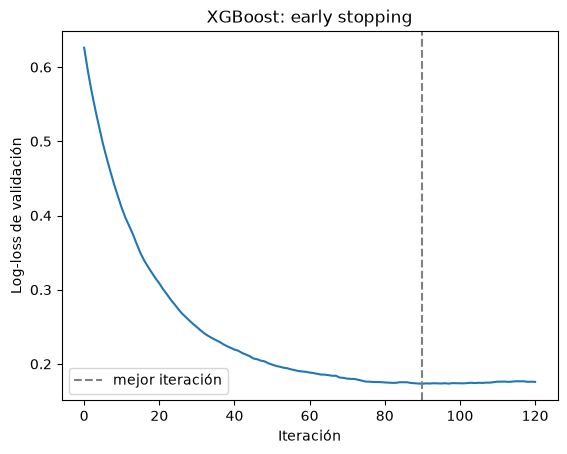

In [36]:
hist = xgb.evals_result()['validation_0']['logloss']
plt.plot(hist)
plt.axvline(xgb.best_iteration, color='gray', linestyle='--', label='mejor iteración')
plt.xlabel('Iteración')
plt.ylabel('Log-loss de validación')
plt.title('XGBoost: early stopping')
plt.legend()
plt.show()

<h3> LightGBM </h3>

**LightGBM** (Microsoft, 2017) está diseñado para ser rápido y eficiente en memoria con datasets grandes. Sus ideas clave:

- **Crecimiento por hojas** (*leaf-wise* / *best-first*): en cada paso divide la hoja con mayor ganancia de todo el árbol, en lugar de crecer nivel por nivel. Produce árboles asimétricos y más profundos para el mismo número de hojas, con menor pérdida, pero **más propensos a sobreajustar en datasets pequeños**.
- **Histogramas**: discretiza las variables continuas en `max_bin` intervalos, acelerando la búsqueda de cortes y reduciendo memoria.
- **GOSS** (*Gradient-based One-Side Sampling*): conserva las observaciones con gradientes grandes y muestrea las de gradientes pequeños.
- **EFB** (*Exclusive Feature Bundling*): agrupa variables dispersas mutuamente excluyentes para reducir dimensionalidad.
- Soporte nativo de **variables categóricas** (se pasan como `category` de pandas o con `categorical_feature`) y de valores faltantes.

**Hiperparámetros principales** (API de scikit-learn)

| Hiperparámetro | Qué controla | Default | Guía |
|---|---|---|---|
| `num_leaves` | Máximo de hojas por árbol. **El parámetro más importante.** | 31 | Controla la complejidad. Mantenerlo `< 2^max_depth`. Valores típicos 15–255; reducirlo si hay sobreajuste. |
| `max_depth` | Profundidad máxima. | -1 (sin límite) | Útil para limitar el crecimiento leaf-wise (p. ej. 4–12). |
| `min_child_samples` (`min_data_in_leaf`) | Observaciones mínimas por hoja. | 20 | Muy efectivo contra el sobreajuste; subirlo (50–200) en datasets grandes o ruidosos. |
| `learning_rate` | Encogimiento por árbol. | 0.1 | 0.01–0.1 con más `n_estimators`. |
| `n_estimators` | Número de árboles. | 100 | Alto + early stopping. |
| `subsample` (`bagging_fraction`) y `subsample_freq` | Fracción de filas y cada cuántas iteraciones se remuestrea. | 1.0 y 0 | **El submuestreo solo se activa si `subsample_freq > 0`** (p. ej. 1). |
| `colsample_bytree` (`feature_fraction`) | Fracción de columnas por árbol. | 1.0 | 0.5–1.0. |
| `reg_lambda` / `reg_alpha` | Regularización L2 / L1. | 0 / 0 | Subirlos reduce la varianza. |
| `min_split_gain` | Ganancia mínima para dividir (análogo a `gamma` de XGBoost). | 0 | Poda de divisiones poco útiles. |
| `max_bin` | Intervalos del histograma. | 255 | Menos bins → más rápido y más regularizado. |
| `class_weight` / `is_unbalance` | Manejo de clases desbalanceadas. | `None` | `'balanced'` o `scale_pos_weight`. |
| Early stopping | `callbacks=[lgb.early_stopping(k)]` en `fit`. | – | Requiere `eval_set`. |

In [37]:
from lightgbm import LGBMClassifier, early_stopping

lgbm = LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=15,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    subsample_freq=1,           # sin esto 'subsample' no tiene efecto
    colsample_bytree=0.8,
    reg_lambda=1.0,
    n_jobs=-1,
    random_state=42,
    verbose=-1,
)

y_pred = evaluar('LightGBM', lgbm, X_tr, y_tr,
                 eval_set=[(X_val, y_val)], eval_metric='binary_logloss',
                 callbacks=[early_stopping(stopping_rounds=30, verbose=False)])
print(f'Mejor iteración: {lgbm.best_iteration_}')
print(classification_report(y_test, y_pred))

Mejor iteración: 82
              precision    recall  f1-score   support

           0       0.76      0.90      0.83        42
           1       0.94      0.83      0.88        72

    accuracy                           0.86       114
   macro avg       0.85      0.87      0.85       114
weighted avg       0.87      0.86      0.86       114



<h3> CatBoost </h3>

**CatBoost** (Yandex, 2017) destaca por su manejo de **variables categóricas** y por ser muy robusto con los hiperparámetros por defecto. Sus ideas clave:

- **Ordered boosting**: para evitar el *prediction shift* (sesgo que aparece cuando los gradientes de una observación se calculan con un modelo que ya la vio en el entrenamiento), usa permutaciones aleatorias de los datos de modo que la predicción de cada observación provenga de un modelo entrenado solo con observaciones anteriores en la permutación.
- **Ordered target statistics**: codifica las variables categóricas con estadísticos del objetivo calculados de forma ordenada, evitando la fuga de información (*target leakage*). Las categorías se pasan directamente con `cat_features`, sin *one-hot* ni *label encoding* previo.
- **Árboles simétricos** (*oblivious trees*): todos los nodos de un mismo nivel usan la misma condición de división. Son un fuerte regularizador, muy rápidos en predicción, y el modelo resultante es compacto.
- Combinaciones automáticas de variables categóricas, valores faltantes y soporte de GPU.

**Hiperparámetros principales**

| Hiperparámetro | Qué controla | Default | Guía |
|---|---|---|---|
| `iterations` (`n_estimators`) | Número de árboles. | 1000 | Alto + `early_stopping_rounds`. |
| `learning_rate` | Encogimiento por árbol. | Automático (según datos e iteraciones) | Si se fija manualmente, 0.01–0.1. |
| `depth` | Profundidad de los árboles simétricos. | 6 | 4–10. Cada nivel duplica las hojas ($2^{depth}$); más de 10 es costoso. |
| `l2_leaf_reg` | Regularización L2 sobre los valores de las hojas. | 3 | Subirlo (5–20) reduce sobreajuste. |
| `random_strength` | Aleatoriedad añadida a la puntuación de las divisiones. | 1 | Mayor valor → más regularización. |
| `bagging_temperature` | Intensidad del bootstrap bayesiano (`bootstrap_type='Bayesian'`). | 1 | 0 = sin variación de pesos; valores mayores → más aleatorio. |
| `subsample` | Fracción de filas (con `bootstrap_type='Bernoulli'` o `'MVS'`). | – | 0.5–1.0. |
| `border_count` (`max_bin`) | Cantidad de cortes por variable numérica. | 254 | Menos → más rápido. |
| `cat_features` | Índices o nombres de columnas categóricas. | `None` | **La razón principal para elegir CatBoost** cuando hay muchas categóricas. |
| `one_hot_max_size` | Categóricas con ≤ este número de valores se codifican one-hot. | 2 | El resto usa target statistics. |
| `grow_policy` | `SymmetricTree`, `Depthwise` o `Lossguide`. | `SymmetricTree` | Con `Lossguide` aplica `max_leaves` como en LightGBM. |
| `auto_class_weights` | Pesos automáticos de clases (`'Balanced'`). | `None` | Datos desbalanceados. |
| `early_stopping_rounds` | Detiene si la métrica de validación no mejora. | – | Requiere `eval_set` en `fit`. |

Ejemplo de uso con variables categóricas (no se ejecuta aquí porque el dataset es numérico):

```python
cat = CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=6,
                         cat_features=['ciudad', 'producto'], verbose=0)
cat.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=50)
```

In [38]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=4,
    l2_leaf_reg=3,
    random_strength=1,
    bagging_temperature=1,
    border_count=254,
    eval_metric='Logloss',
    early_stopping_rounds=30,
    random_seed=42,
    verbose=0,
    allow_writing_files=False,  # evita crear la carpeta catboost_info/
)

y_pred = evaluar('CatBoost', cat, X_tr, y_tr, eval_set=(X_val, y_val))
print(f'Mejor iteración: {cat.get_best_iteration()}')
print(classification_report(y_test, y_pred))

Mejor iteración: 91
              precision    recall  f1-score   support

           0       0.78      0.90      0.84        42
           1       0.94      0.85      0.89        72

    accuracy                           0.87       114
   macro avg       0.86      0.88      0.86       114
weighted avg       0.88      0.87      0.87       114



<h3> XGBoost vs LightGBM vs CatBoost </h3>

| | XGBoost | LightGBM | CatBoost |
|---|---|---|---|
| Crecimiento del árbol | Por niveles (`depthwise`); también `lossguide` | Por hojas (*leaf-wise*) | Simétrico (*oblivious*) por defecto |
| Parámetro de complejidad clave | `max_depth` | `num_leaves` | `depth` |
| Variables categóricas | Soporte experimental (`enable_categorical=True`) | Nativo (`categorical_feature`) | Nativo y es su fortaleza (`cat_features`) |
| Regularización principal | `reg_lambda`, `reg_alpha`, `gamma` | `reg_lambda`, `reg_alpha`, `min_child_samples` | `l2_leaf_reg`, `random_strength`, árboles simétricos |
| Velocidad en datasets grandes | Rápido | Generalmente el más rápido | Rápido (muy rápido en GPU y en predicción) |
| Sensibilidad a hiperparámetros | Media | Alta en datasets pequeños (sobreajusta fácil) | Baja: buenos resultados con los valores por defecto |

Ninguno es siempre el mejor: en datos tabulares suelen quedar muy cerca, y las diferencias dependen del tamaño del dataset, la cantidad de variables categóricas y el tiempo de ajuste disponible.

<h2> Ajuste de hiperparámetros en boosting </h2>

Una receta práctica, válida para XGBoost, LightGBM, CatBoost y `GradientBoosting`:

1. **Fijar `learning_rate` moderado (0.05–0.1)** y `n_estimators` alto con **early stopping** sobre un conjunto de validación; así el número de árboles deja de ser un hiperparámetro a buscar.
2. **Complejidad del árbol:** `max_depth` / `num_leaves` / `depth` y `min_child_weight` / `min_child_samples`. Son los que más impactan el sesgo–varianza.
3. **Aleatoriedad:** `subsample` y `colsample_bytree` (0.6–1.0).
4. **Regularización:** `reg_lambda`, `reg_alpha`, `gamma` / `min_split_gain` / `l2_leaf_reg`.
5. **Al final, bajar `learning_rate`** (p. ej. a 0.01–0.02) y volver a determinar el número de árboles con early stopping para exprimir un poco más de desempeño.

Para espacios de búsqueda grandes, `RandomizedSearchCV` es más eficiente que `GridSearchCV`; para tuning serio, librerías como Optuna. Ejemplo con LightGBM:

In [39]:
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'num_leaves': randint(4, 40),
    'min_child_samples': randint(5, 40),
    'learning_rate': loguniform(0.01, 0.3),
    'subsample': uniform(0.6, 0.4),          # [0.6, 1.0]
    'colsample_bytree': uniform(0.6, 0.4),   # [0.6, 1.0]
    'reg_lambda': loguniform(1e-2, 10),
}

search = RandomizedSearchCV(
    LGBMClassifier(n_estimators=200, subsample_freq=1, random_state=42, verbose=-1),
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print('Mejores parámetros:', search.best_params_)
print(f'Exactitud CV: {search.best_score_:.3f}')
evaluar('LightGBM (RandomizedSearchCV)', search.best_estimator_);

Mejores parámetros: {'colsample_bytree': np.float64(0.6943939678995823), 'learning_rate': np.float64(0.02389152997793864), 'min_child_samples': 31, 'num_leaves': 12, 'reg_lambda': np.float64(1.3551540552976564), 'subsample': np.float64(0.6443563283247326)}
Exactitud CV: 0.938


<h2> Stacking </h2>

En *stacking* un **meta-modelo** (`final_estimator`) aprende a combinar las predicciones de modelos base heterogéneos. Para evitar fuga de información, el meta-modelo se entrena con predicciones *out-of-fold* de los modelos base (parámetro `cv`). Es el método más flexible, pero también el más costoso y propenso a sobreajuste si el meta-modelo es complejo; por eso se suele usar uno simple (regresión logística / lineal).

In [40]:
from sklearn.ensemble import StackingClassifier

stack = StackingClassifier(
    estimators=[
        ('lr', con_escala(LogisticRegression())),
        ('svc', con_escala(SVC(probability=True, random_state=42))),
        ('rf', RandomForestClassifier(n_estimators=200, random_state=0)),
    ],
    final_estimator=LogisticRegression(),
    cv=5,
    n_jobs=-1,
)
evaluar('Stacking', stack);

<h2> Comparación de modelos </h2>

In [41]:
evaluar('Voting (hard)', voting_clf)
evaluar('Voting (soft)', soft_clf)

(pd.DataFrame(resultados).T
   .sort_values('accuracy', ascending=False)
   .round(3))

,accuracy,f1,tiempo_fit_s
Random Forest,0.921,0.936,0.189
Bagging (árboles),0.895,0.913,0.033
LightGBM (RandomizedSearchCV),0.895,0.914,0.017
Gradient Boosting (sklearn),0.895,0.913,0.043
AdaBoost,0.886,0.905,0.114
Árbol de decisión,0.886,0.905,0.001
XGBoost,0.886,0.906,0.336
Stacking,0.877,0.899,0.649
Voting (hard),0.877,0.899,0.006
Voting (soft),0.877,0.899,0.008


**Cómo leer esta tabla:** el conjunto de prueba tiene solo 114 observaciones, por lo que una diferencia de 1–2 aciertos no es estadísticamente significativa; y XGBoost, LightGBM y CatBoost se entrenaron con el 80 % del conjunto de entrenamiento (el resto se reservó para el early stopping). Para una comparación seria se debe usar validación cruzada repetida, y los tiempos de un dataset tan pequeño no son representativos: las diferencias de velocidad de LightGBM/XGBoost aparecen con cientos de miles de filas.

**¿Qué método elegir?**

- **Random Forest:** excelente punto de partida; pocos hiperparámetros sensibles, difícil de sobreajustar, estimación OOB gratis.
- **AdaBoost:** simple y didáctico; útil con stumps en problemas limpios, pero sensible al ruido; en la práctica suele superarlo Gradient Boosting.
- **Gradient Boosting (XGBoost / LightGBM / CatBoost):** estado del arte en datos tabulares. Elegir **LightGBM** para datasets grandes y velocidad, **XGBoost** como opción estable y muy documentada, y **CatBoost** cuando hay muchas variables categóricas o se quiere un buen desempeño con poco ajuste.
- **Voting / Stacking:** cuando se tienen modelos de naturaleza distinta con errores poco correlacionados.